In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")

analyzer = SentimentIntensityAnalyzer()

In [2]:
df["headline_polarity"] = df["headline"].apply(
    lambda x: analyzer.polarity_scores(x)["compound"]
)

df["body_polarity"] = df["body_text"].apply(
    lambda x: analyzer.polarity_scores(x)["compound"]
)

print(df[["headline_polarity", "body_polarity"]].head())

   headline_polarity  body_polarity
0            -0.4215            0.0
1            -0.5106            0.0
2             0.0000            0.0
3            -0.4767            0.0
4            -0.4939            0.0


In [3]:
df["polarity_shift"] = (
    df["headline_polarity"] - df["body_polarity"]
)

def identify_shift(value):
    if value > 0.05:
        return "Headline More Positive"
    elif value < -0.05:
        return "Headline More Negative"
    else:
        return "Similar Polarity"

df["shift_type"] = df["polarity_shift"].apply(identify_shift)

print(df[["label", "polarity_shift", "shift_type"]].head())

  label  polarity_shift              shift_type
0  Real         -0.4215  Headline More Negative
1  Real         -0.5106  Headline More Negative
2  Fake          0.0000        Similar Polarity
3  Fake         -0.4767  Headline More Negative
4  Real         -0.4939  Headline More Negative


In [4]:
comparison = pd.crosstab(
    df["label"],
    df["shift_type"],
    normalize="index"
) * 100

print(comparison.round(2))

shift_type  Headline More Negative  Headline More Positive  Similar Polarity
label                                                                       
Fake                         42.79                   32.61             24.59
Real                         43.65                   32.94             23.41


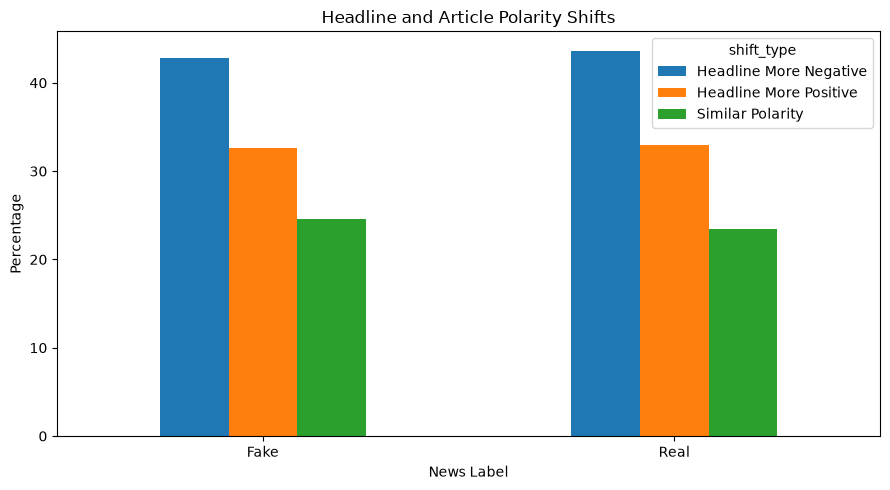

In [5]:
comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Headline and Article Polarity Shifts")
plt.xlabel("News Label")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
df.to_csv("T39_polarity_shift_analysis.csv", index=False)
comparison.to_csv("T39_polarity_comparison.csv")
